In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
from matplotlib import pyplot as plt

from src.utils import load_data, save_data
from src.utils import build_histogramme, drop_constant_features, drop_correlated_features
from src.utils import make_binary_target, class_distribution, split_data
from src.utils import plot_class_distribution, plot_correlation_matrix, plot_histograms, plot_boxplots

PS2 = load_data("data/raw/PS2.txt")
FS1 = load_data("data/raw/FS1.txt")
profile = load_data("data/raw/profile.txt")

print("PS2    :", PS2.shape, "(cycles x points)")
print("FS1    :", FS1.shape, "(cycles x points)")
print("profile:", profile.shape, "(cycles x conditions)")

PS2    : (2205, 6000) (cycles x points)
FS1    : (2205, 600) (cycles x points)
profile: (2205, 5) (cycles x conditions)


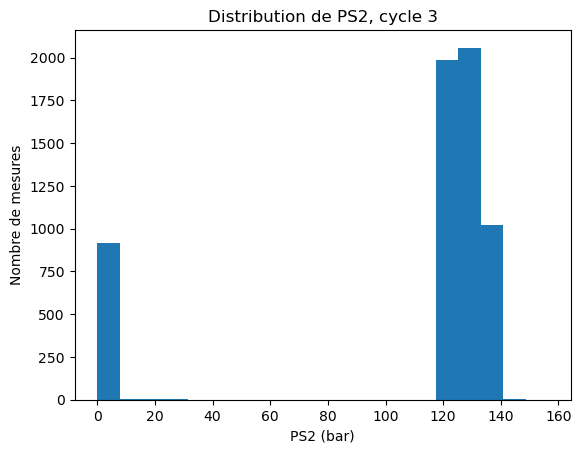

In [2]:
# Un cycle = un histogramme : exemple sur le cycle 3
plt.hist(PS2.iloc[3], bins=20)
plt.xlabel("PS2 (bar)")
plt.ylabel("Nombre de mesures")
plt.title("Distribution de PS2, cycle 3")
plt.show()

In [3]:
# Chaque cycle devient un histogramme : proportion de mesures par intervalle (20 intervalles)
X = pd.concat(
    [
        build_histogramme(PS2, bins=20, prefix="ps2_"),
        build_histogramme(FS1, bins=20, prefix="fs1_"),
    ],
    axis=1,
)
print(X.shape)
X.head()

(2205, 40)


,ps2_bin_0,ps2_bin_1,ps2_bin_2,ps2_bin_3,ps2_bin_4,ps2_bin_5,ps2_bin_6,ps2_bin_7,ps2_bin_8,ps2_bin_9,...,fs1_bin_10,fs1_bin_11,fs1_bin_12,fs1_bin_13,fs1_bin_14,fs1_bin_15,fs1_bin_16,fs1_bin_17,fs1_bin_18,fs1_bin_19
0,0.153000,0.001333,0.000333,0.000000,0.000167,0.0,0.000167,0.000000,0.0,0.000000,...,0.006667,0.001667,0.003333,0.001667,0.001667,0.001667,0.0,0.0,0.001667,0.0
1,0.152667,0.001500,0.000333,0.000167,0.000167,0.0,0.000000,0.000167,0.0,0.000000,...,0.008333,0.001667,0.003333,0.001667,0.000000,0.001667,0.0,0.0,0.001667,0.0
2,0.153167,0.001167,0.000167,0.000333,0.000000,0.0,0.000000,0.000167,0.0,0.000000,...,0.006667,0.001667,0.005000,0.001667,0.000000,0.001667,0.0,0.0,0.001667,0.0
3,0.153333,0.000833,0.000333,0.000333,0.000000,0.0,0.000000,0.000167,0.0,0.000167,...,0.006667,0.001667,0.003333,0.001667,0.001667,0.001667,0.0,0.0,0.001667,0.0
4,0.152667,0.001333,0.000500,0.000333,0.000000,0.0,0.000000,0.000167,0.0,0.000000,...,0.006667,0.001667,0.003333,0.000000,0.001667,0.001667,0.0,0.0,0.001667,0.0


In [17]:
X.describe()

,ps2_bin_0,ps2_bin_13,ps2_bin_14,ps2_bin_15,ps2_bin_16,fs1_bin_0,fs1_bin_4,fs1_bin_5,fs1_bin_6,fs1_bin_8,fs1_bin_9,fs1_bin_10,fs1_bin_11,fs1_bin_12
count,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000
mean,0.154398,0.049130,0.304112,0.285109,0.150044,0.158451,0.003943,0.003136,0.006209,0.013936,0.005992,0.003607,0.001889,0.002122
std,0.001767,0.068021,0.076375,0.119332,0.050129,0.004177,0.001648,0.002212,0.006044,0.006012,0.002454,0.001209,0.001135,0.001170
min,0.152167,0.000000,0.011000,0.005333,0.004167,0.153333,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.153000,0.000167,0.265667,0.335333,0.166000,0.155000,0.003333,0.001667,0.005000,0.010000,0.005000,0.003333,0.001667,0.001667
50%,0.153500,0.000167,0.328333,0.336667,0.167500,0.156667,0.003333,0.003333,0.005000,0.015000,0.006667,0.003333,0.001667,0.001667
75%,0.155667,0.143667,0.337833,0.342500,0.169000,0.160000,0.005000,0.005000,0.006667,0.018333,0.008333,0.003333,0.003333,0.003333
max,0.160000,0.152500,0.520833,0.418667,0.170333,0.176667,0.008333,0.010000,0.105000,0.065000,0.011667,0.008333,0.005000,0.005000


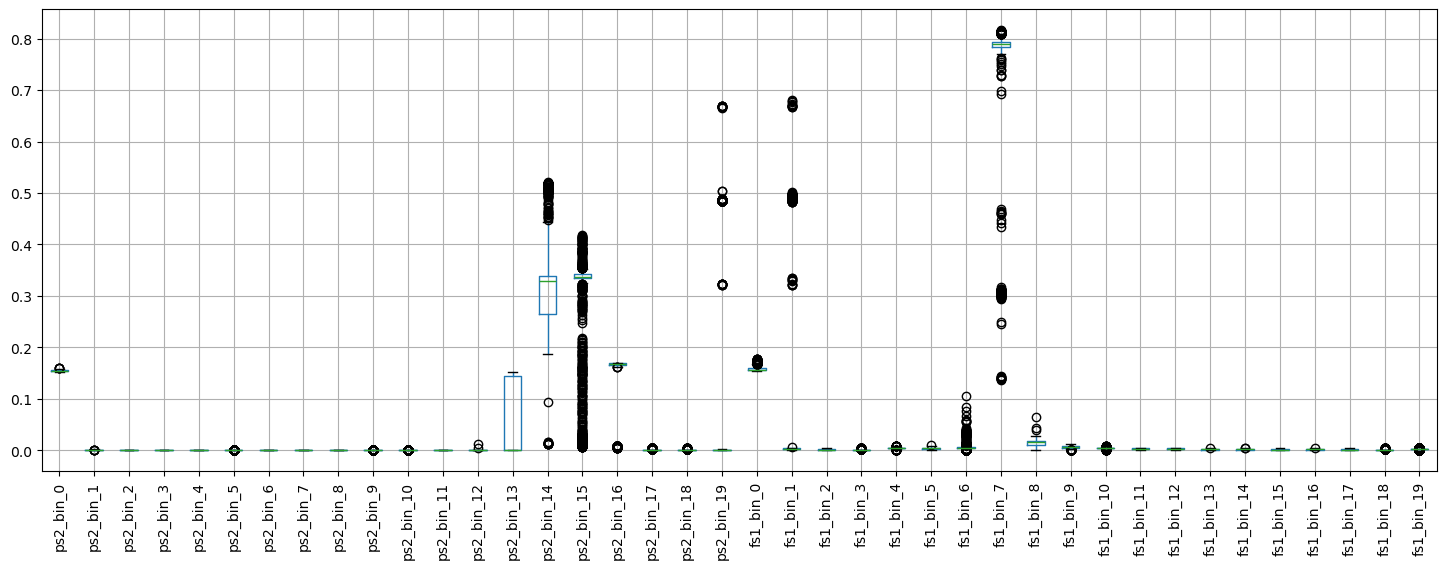

In [5]:
plot_boxplots(X)

In [6]:
y = make_binary_target(profile[1], positive_value=100, name="valve_optimal")
y.head()

0    1
1    1
2    1
3    1
4    1
Name: valve_optimal, dtype: int64

In [7]:
# Features constantes ou quasi constantes (intervalles jamais atteints)
X, constant_cols = drop_constant_features(X, threshold=1e-3)
print("Supprimées :", constant_cols)

Supprimées : ['ps2_bin_1', 'ps2_bin_2', 'ps2_bin_3', 'ps2_bin_4', 'ps2_bin_5', 'ps2_bin_6', 'ps2_bin_7', 'ps2_bin_8', 'ps2_bin_9', 'ps2_bin_10', 'ps2_bin_11', 'ps2_bin_12', 'ps2_bin_17', 'ps2_bin_18', 'fs1_bin_2', 'fs1_bin_3', 'fs1_bin_13', 'fs1_bin_14', 'fs1_bin_15', 'fs1_bin_16', 'fs1_bin_17', 'fs1_bin_18', 'fs1_bin_19']


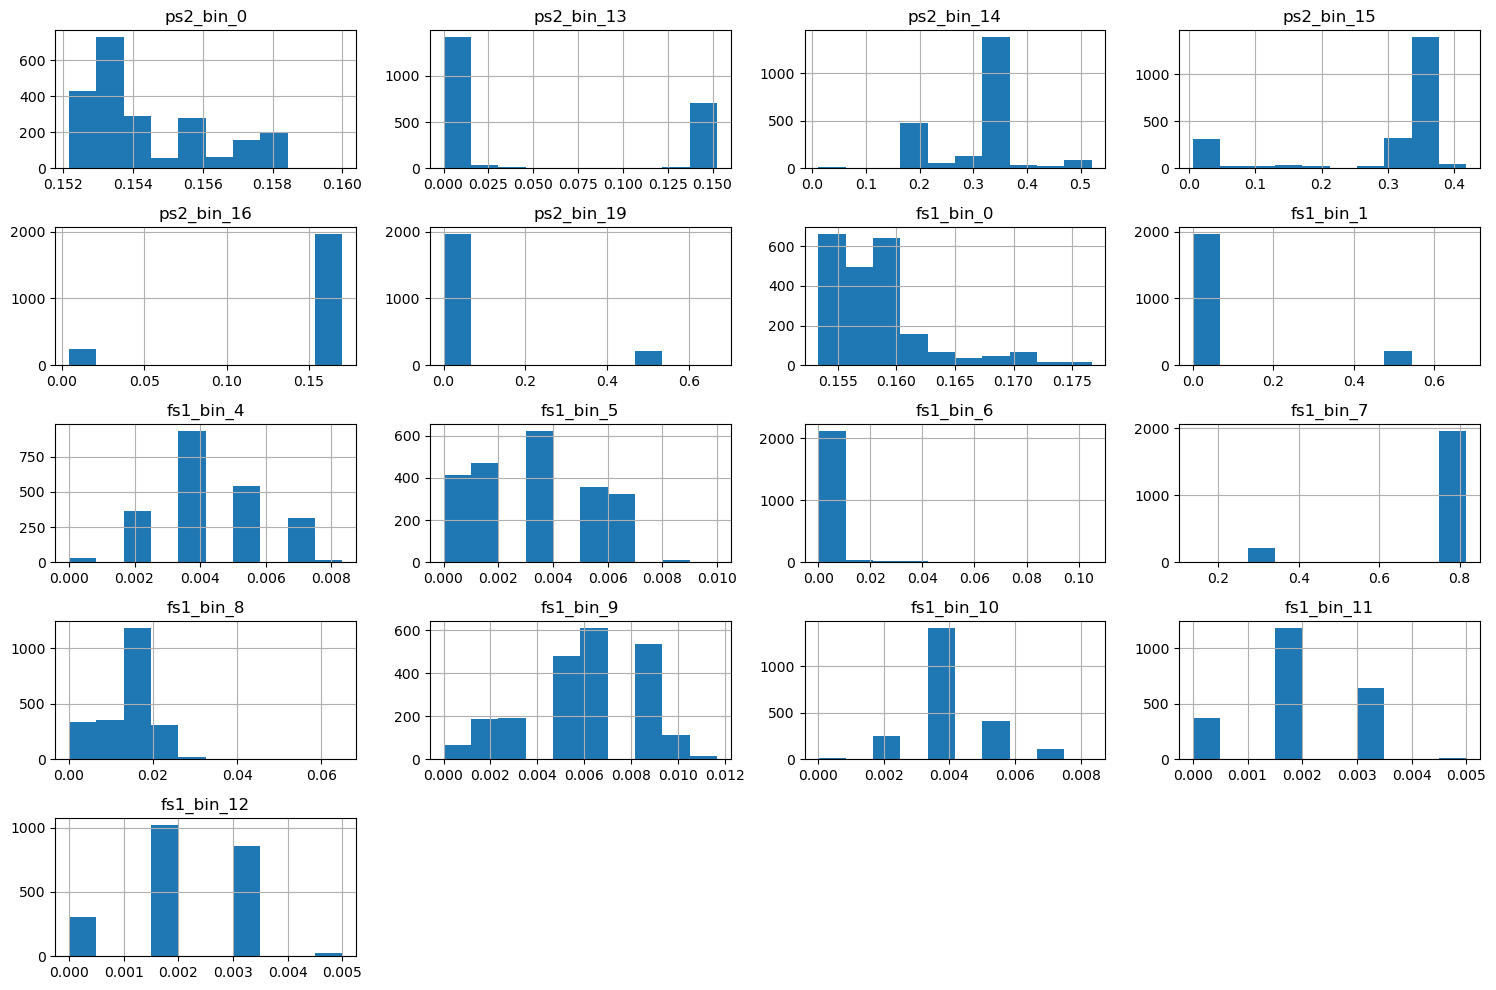

In [8]:
plot_histograms(X, save_as="histogramme_features_histo.png")

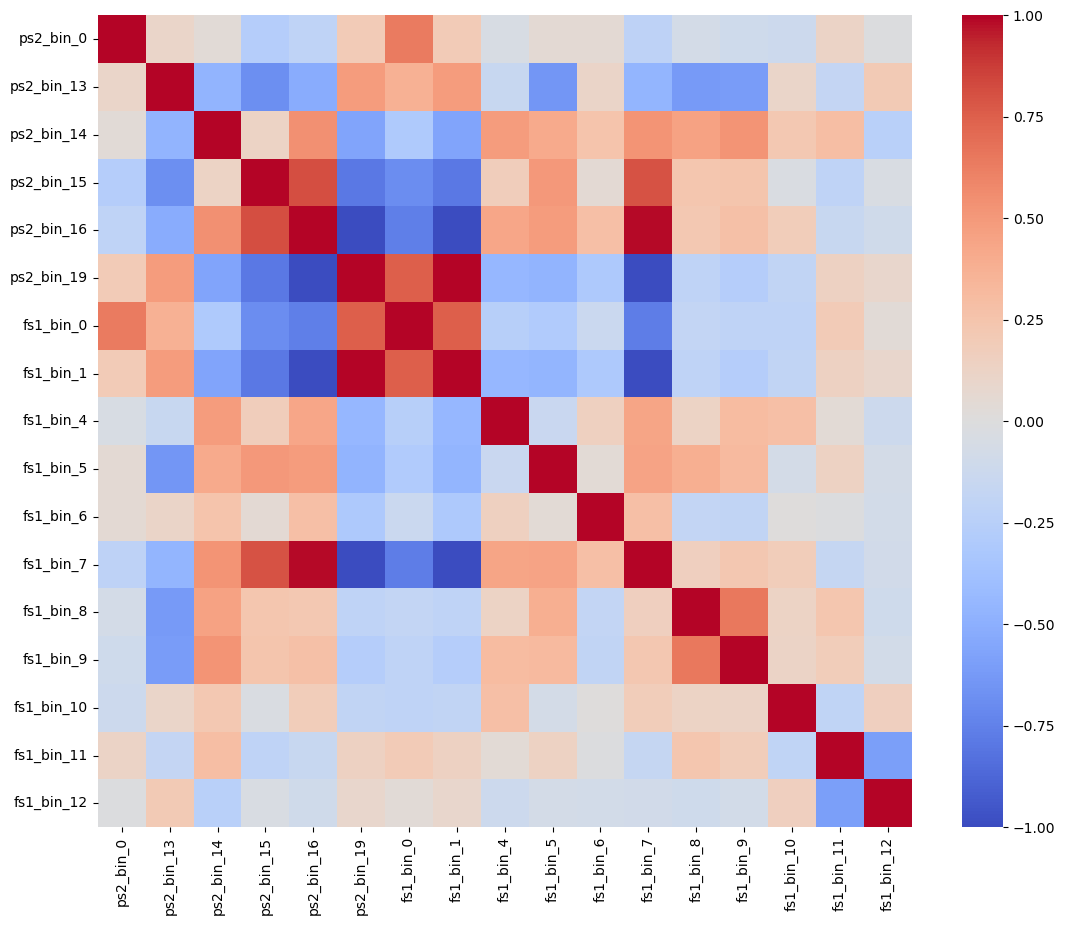

In [9]:
plot_correlation_matrix(X, save_as="matrice_correlation_histo.png", annot=False)

In [10]:
# Une seule feature par paire fortement corrélée (|corr| > 0.85)
X, to_drop = drop_correlated_features(X, threshold=0.85)
print("Supprimées :", to_drop)
print("Features conservées :", X.shape[1], list(X.columns))

Supprimées : ['ps2_bin_19', 'fs1_bin_1', 'fs1_bin_7']
Features conservées : 14 ['ps2_bin_0', 'ps2_bin_13', 'ps2_bin_14', 'ps2_bin_15', 'ps2_bin_16', 'fs1_bin_0', 'fs1_bin_4', 'fs1_bin_5', 'fs1_bin_6', 'fs1_bin_8', 'fs1_bin_9', 'fs1_bin_10', 'fs1_bin_11', 'fs1_bin_12']


In [11]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
ps2_bin_0,2205.0,0.154398,0.001767,0.152167,0.153000,0.153500,0.155667,0.160000
ps2_bin_13,2205.0,0.049130,0.068021,0.000000,0.000167,0.000167,0.143667,0.152500
ps2_bin_14,2205.0,0.304112,0.076375,0.011000,0.265667,0.328333,0.337833,0.520833
ps2_bin_15,2205.0,0.285109,0.119332,0.005333,0.335333,0.336667,0.342500,0.418667
ps2_bin_16,2205.0,0.150044,0.050129,0.004167,0.166000,0.167500,0.169000,0.170333
fs1_bin_0,2205.0,0.158451,0.004177,0.153333,0.155000,0.156667,0.160000,0.176667
fs1_bin_4,2205.0,0.003943,0.001648,0.000000,0.003333,0.003333,0.005000,0.008333
fs1_bin_5,2205.0,0.003136,0.002212,0.000000,0.001667,0.003333,0.005000,0.010000
fs1_bin_6,2205.0,0.006209,0.006044,0.000000,0.005000,0.005000,0.006667,0.105000
fs1_bin_8,2205.0,0.013936,0.006012,0.000000,0.010000,0.015000,0.018333,0.065000


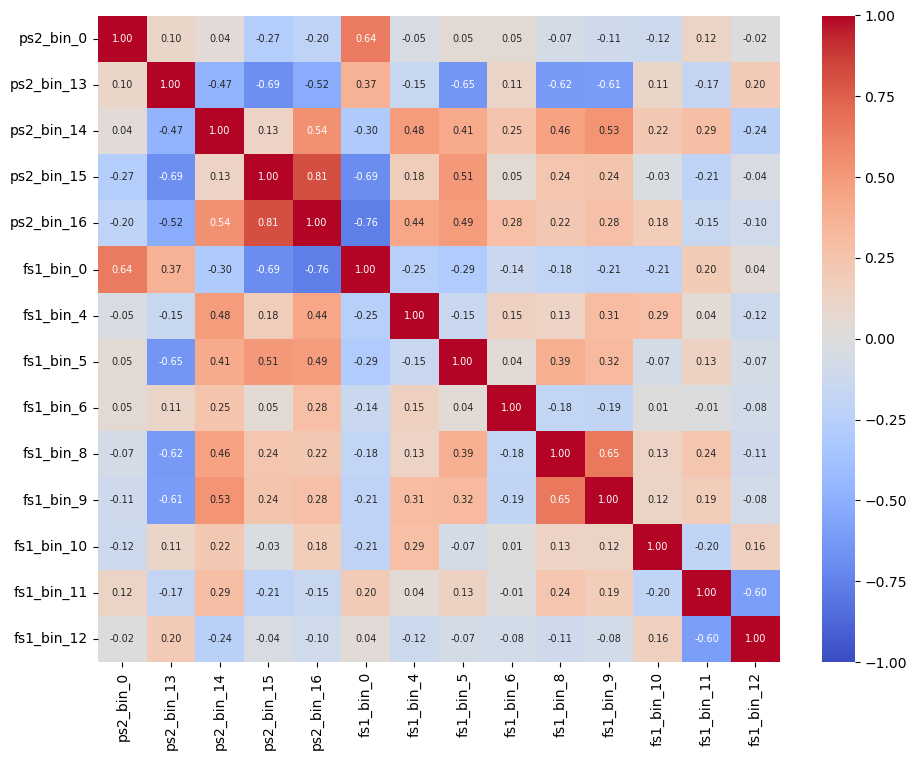

In [12]:
plot_correlation_matrix(X, save_as="matrice_correlation_finale_histo.png")

In [13]:
# Découpage mélangé et stratifié (test = 20 %, même découpage que les autres jeux)
x_train, x_test, y_train, y_test = split_data(X, y, test_size=0.2)
pd.concat({"train": class_distribution(y_train), "test": class_distribution(y_test)}, axis=1)

train       test      
                  n     %    n     %
valve_optimal                       
0               864  49.0  216  49.0
1               900  51.0  225  51.0

In [14]:
print(X.shape, y.shape)
save_data(x_train, x_test, y_train, y_test, name="histogramme")

(2205, 14) (2205,)


WindowsPath('C:/Users/noumo/Desktop/EFREI/Machine learning/projetML/hydraulic-valve-predictive-maintenance/data/processed/histogramme')